In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

In [ ]:
# The first run downloads the dataset from scikit-learn's data repository.
housing = fetch_california_housing(as_frame=True)
df = housing.frame
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [ ]:
print('Dataset shape:', df.shape)
print('\nColumn names:')
print(df.columns.tolist())
print('\nMissing values:')
print(df.isnull().sum())
print('\nSummary statistics:')
df.describe().round(2)

Dataset shape: (20640, 9)

Column names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']

Missing values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Summary statistics:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57,2.07
std,1.90,12.59,2.47,0.47,1132.46,10.39,2.14,2.00,1.15
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35,0.15
25%,2.56,18.00,4.44,1.01,787.00,2.43,33.93,-121.80,1.20
50%,3.53,29.00,5.23,1.05,1166.00,2.82,34.26,-118.49,1.80
75%,4.74,37.00,6.05,1.10,1725.00,3.28,37.71,-118.01,2.65
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31,5.00


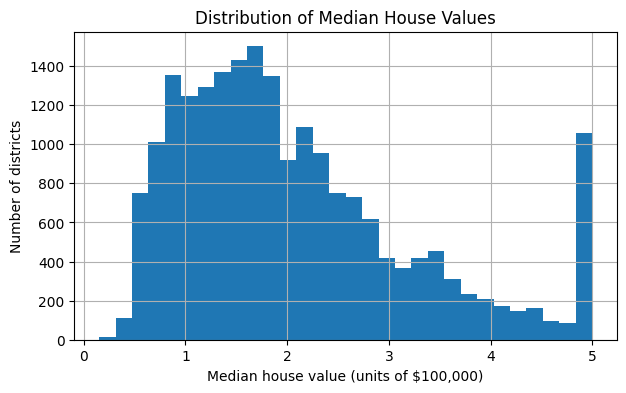

In [ ]:
df['MedHouseVal'].hist(bins=30, figsize=(7, 4))
plt.xlabel('Median house value (units of $100,000)')
plt.ylabel('Number of districts')
plt.title('Distribution of Median House Values')
plt.show()

In [ ]:
X = df.drop(columns='MedHouseVal')
y = df['MedHouseVal']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print('Training rows:', X_train.shape[0])
print('Testing rows:', X_test.shape[0])

Training rows: 16512
Testing rows: 4128


In [ ]:
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
model.fit(X_train, y_train)
print('Model training completed.')

Model training completed.


In [ ]:
y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
print(f'MAE:  {mae:.3f} (units of $100,000)')
print(f'RMSE: {rmse:.3f} (units of $100,000)')
print(f'R²:   {r2:.3f}')

MAE:  0.328 (units of $100,000)
RMSE: 0.505 (units of $100,000)
R²:   0.805


In [ ]:
comparison = pd.DataFrame({'Actual': y_test.values, 'Predicted': y_pred})
comparison.head(10)

,Actual,Predicted
0,0.47700,0.509500
1,0.45800,0.741610
2,5.00001,4.923257
3,2.18600,2.529610
4,2.78000,2.273690
5,1.58700,1.646920
6,1.98200,2.376050
7,1.57500,1.669320
8,3.40000,2.772971
9,4.46600,4.913459


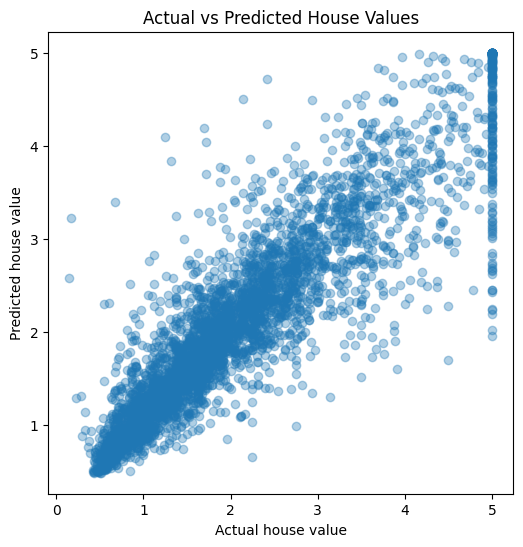

In [ ]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.35)
plt.xlabel('Actual house value')
plt.ylabel('Predicted house value')
plt.title('Actual vs Predicted House Values')
plt.show()

MedInc        0.524871
AveOccup      0.138443
Latitude      0.088936
Longitude     0.088629
HouseAge      0.054593
AveRooms      0.044272
Population    0.030650
AveBedrms     0.029606
dtype: float64


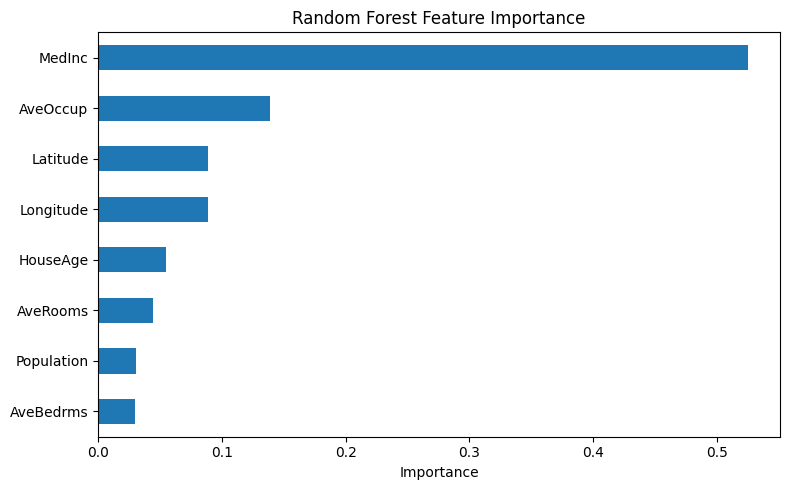

In [ ]:
importance = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
print(importance)
importance.sort_values().plot(kind='barh', figsize=(8, 5), title='Random Forest Feature Importance')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

In [ ]:
sample_district = X_test.iloc[[0]]
predicted_value = model.predict(sample_district)[0]
print(f'Predicted median house value: ${predicted_value * 100000:,.0f}')
print('Input features:')
display(sample_district)

Predicted median house value: $50,950
Input features:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
20046,1.6812,25.0,4.192201,1.022284,1392.0,3.877437,36.06,-119.01


1. What is Random Forest?

Random Forest is a Supervised Machine Learning Algorithm that uses multiple Decision Trees to make accurate predictions.

Instead of using only one decision tree, it creates many decision trees and combines their results to get the final answer.

Simple example:

Suppose we want to predict whether a student will Pass or Fail based on attendance, study hours and previous marks.
- Decision Tree 1 → Pass
- Decision Tree 2 → Fail
- Decision Tree 3 → Pass
- Decision Tree 4 → Pass
- Decision Tree 5 → Fail
The final prediction is Pass, because most decision trees predicted Pass.

Why and When Do We Use Random Forest?

Why do we use Random Forest?
1. High Accuracy: It combines multiple decision trees to improve prediction.
2. Reduces Overfitting: It reduces the chance of memorizing training data compared to a single decision tree.
3. Handles Large Data: It can work with datasets containing many records and features.
4. Easy to Use: It can be used for different types of prediction problems.
5. Feature Importance: It helps us identify which features are important for making predictions.
When do we use Random Forest?
We use Random Forest when:
- We want to predict whether something is Yes or No.
- We want to predict categories like Pass or Fail.
- We want to predict numerical values like house prices.
- We have a dataset with multiple features.
- A single decision tree is not giving good results.

Working of Random Forest?

Random Forest works in five simple steps


Step 1: Dataset Selection

First, we collect the dataset containing input features and output values.

Example: Student attendance, study hours and previous marks.

Step 2: Bootstrap Sampling

The algorithm randomly selects different samples from the original dataset.

Step 3: Building Decision Trees

It creates multiple decision trees using different samples and random subsets of features.

Step 4: Making Predictions

Each decision tree makes its own prediction.

Example:
- Tree 1 → Pass
- Tree 2 → Fail
- Tree 3 → Pass
- Tree 4 → Pass
Step 5: Final Prediction

All decision trees combine their results to give the final prediction.
- Classification → Majority Voting.
- Regression → Average of predictions.